In [1]:
import scanpy as sc
import numpy as np

# Load
healthy_path = r"C:\Users\Liyua\Documents\healthy"
ipf_path = r"C:\Users\Liyua\Documents\IPF"

adata_h = sc.read_10x_mtx(healthy_path, var_names='gene_symbols')
adata_i = sc.read_10x_mtx(ipf_path, var_names='gene_symbols')

adata_h.obs['condition'] = 'healthy'
adata_i.obs['condition'] = 'IPF'

adata = adata_h.concatenate(adata_i)

# Clean inf/nan
adata.X.data[np.isnan(adata.X.data)] = 0
adata.X.data[np.isinf(adata.X.data)] = 0

# Hard clip extremely high counts
adata.X.data = np.clip(adata.X.data, 0, 100)

# remove genes with zero mean
gene_means_sparse = np.array(adata.X.mean(axis=0)).flatten()
nonzero_genes = gene_means_sparse > 0
adata = adata[:, nonzero_genes]

print(f"After removing zero-mean genes: {adata.shape[1]} genes left.")

# convert to dense
if not isinstance(adata.X, np.ndarray):
    Xdense = adata.X.toarray()
else:
    Xdense = adata.X.copy()

# manual highly-variable selection
gene_means = Xdense.mean(axis=0)
gene_vars = Xdense.var(axis=0)
gene_means[gene_means == 0] = 1e-6
dispersion = gene_vars / gene_means

top_idx = np.argsort(dispersion)[::-1][:2000]
selected_genes = adata.var_names[top_idx]

adata = adata[:, selected_genes]
print(f"Selected {adata.shape[1]} highly variable genes manually.")

# Normalize and scale
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.scale(adata, max_value=10)

# again, replace any nan/inf
if not isinstance(adata.X, np.ndarray):
    Xdense = adata.X.toarray()
else:
    Xdense = adata.X.copy()
Xdense[~np.isfinite(Xdense)] = 0

# features
X = Xdense

# labels
y = np.array(adata.obs['condition'] == "IPF").astype(int)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

with open("2000_hvg_gene_names.txt", "w") as f:
    for g in selected_genes:
        f.write(f"{g}\n")
print(f"Saved {len(selected_genes)} highly variable gene names to 2000_hvg_gene_names.txt")


C:\Users\Liyua\AppData\Local\Temp\ipykernel_31504\3469755974.py:14: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = adata_h.concatenate(adata_i)


After removing zero-mean genes: 23675 genes left.
Selected 2000 highly variable genes manually.


C:\Users\Liyua\anaconda3\Lib\site-packages\scanpy\preprocessing\_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
C:\Users\Liyua\anaconda3\Lib\functools.py:907: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


X shape: (7985, 2000)
y shape: (7985,)
Saved 2000 highly variable gene names to 2000_hvg_gene_names.txt


In [3]:
import pandas as pd

# load
morph = pd.read_csv("morphology_latent_vectors.csv", header=None)
gene = pd.read_csv("gene_latent_vectors_89_updated.csv", header=None)

# confirm shapes
print("morph shape:", morph.shape)
print("gene shape:", gene.shape)

# merge
merged = pd.concat([morph, gene], axis=1)

# save
merged.to_csv("merged_latent_vectors.csv", index=False)

print("merged_latent_vectors.csv created with shape", merged.shape)


morph shape: (90, 64)
gene shape: (90, 64)
merged_latent_vectors.csv created with shape (90, 128)


In [5]:
import pandas as pd
import numpy as np

# load fused latent vectors
fused = pd.read_csv("fused_shared_latent_vectors.csv", header=None).values

# load 2000 gene names
gene_names = [line.strip() for line in open("2000_hvg_gene_names.txt")]

# get the 2000 gene x cells matrix directly from adata
# assuming you still have 'adata' in RAM
X = adata[:, gene_names].X.toarray()

# check
print(f"fused shape: {fused.shape}, X shape: {X.shape}")


fused shape: (92, 32), X shape: (7985, 2000)


In [6]:
import torch
import torch.nn as nn

class GeneAutoencoder(nn.Module):
    def __init__(self, input_dim=2000, latent_dim=64):
        super(GeneAutoencoder, self).__init__()

        self.enc = nn.Sequential(
            nn.Linear(input_dim, 512),  # enc.0
            nn.ReLU(),
            nn.Linear(512, 128),        # enc.2
            nn.ReLU(),
            nn.Linear(128, latent_dim)  # enc.4
        )
        
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 128), # dec.0
            nn.ReLU(),
            nn.Linear(128, 512),        # dec.2
            nn.ReLU(),
            nn.Linear(512, input_dim)   # dec.4
        )
        
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),  # classifier.0
            nn.ReLU(),
            nn.Linear(32, 1)            # classifier.2
        )

    def forward(self, x):
        z = self.enc(x)
        recon = self.dec(z)
        logits = self.classifier(z)
        return recon, logits

gene_autoencoder = GeneAutoencoder()
gene_autoencoder.load_state_dict(torch.load("gene_autoencoder_weights.pth"))
gene_autoencoder.eval()

GeneAutoencoder(
  (enc): Sequential(
    (0): Linear(in_features=2000, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
  )
  (dec): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=2000, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [7]:
import torch
import numpy as np
import pandas as pd

# reload the autoencoder class
class GeneAutoencoder(torch.nn.Module):
    def __init__(self):
        super(GeneAutoencoder, self).__init__()
        self.enc = torch.nn.Sequential(
            torch.nn.Linear(2000, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 64)
        )
        self.dec = torch.nn.Sequential(
            torch.nn.Linear(64, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 2000)
        )
        self.classifier = torch.nn.Sequential(
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 1)
        )

    def forward(self, x):
        z = self.enc(x)
        recon = self.dec(z)
        yhat = self.classifier(z)
        return recon, yhat

# load
gene_autoencoder = GeneAutoencoder()
gene_autoencoder.load_state_dict(torch.load("gene_autoencoder_weights.pth"))
gene_autoencoder.eval()

# get the first encoder weight matrix (512 x 2000)
W1 = gene_autoencoder.enc[0].weight.detach().cpu().numpy()  # (512, 2000)

# second layer (128 x 512)
W2 = gene_autoencoder.enc[2].weight.detach().cpu().numpy()  # (128, 512)

# third layer to latent (64 x 128)
W3 = gene_autoencoder.enc[4].weight.detach().cpu().numpy()  # (64, 128)

# combine: (64 x 2000) = W3 x W2 x W1
combined_weights = W3 @ W2 @ W1  # (64, 2000)

# get gene names
with open("2000_hvg_gene_names.txt") as f:
    gene_names = [line.strip() for line in f]

# check shapes
print(f"combined_weights shape: {combined_weights.shape}")  # should be (64,2000)
print(f"gene_names length: {len(gene_names)}")             # should be 2000

# for each latent dimension, rank top 10 contributing genes
results = {}
for latent_dim in range(64):
    weights = combined_weights[latent_dim, :]
    top_idx = np.argsort(np.abs(weights))[::-1][:10]  # top 10 absolute
    top_genes = [gene_names[i] for i in top_idx]
    top_weights = weights[top_idx]
    results[f"latent_{latent_dim}"] = list(zip(top_genes, top_weights))

# save as CSV
with open("latent_top_genes.csv", "w") as f:
    f.write("LatentDimension,Gene,Weight\n")
    for latent, genes in results.items():
        for gene, weight in genes:
            f.write(f"{latent},{gene},{weight}\n")

print("saved latent_top_genes.csv with top 10 genes per latent dimension")


combined_weights shape: (64, 2000)
gene_names length: 2000
saved latent_top_genes.csv with top 10 genes per latent dimension


In [36]:
import pandas as pd
import gseapy as gp
import time

# load
df = pd.read_csv("latent_top_genes.csv")
latents = df['LatentDimension'].unique()
library = "GO_Biological_Process_2021"

for latent in latents:
    genes = df[df['LatentDimension'] == latent]['Gene'].tolist()
    try:
        enr = gp.enrichr(
            gene_list=genes,
            gene_sets=library,
            organism="Human",
            outdir=None,
            no_plot=True
        )
        res = enr.results
        if res is not None and not res.empty:
            go_terms = res[['Term', 'Adjusted P-value', 'Overlap', 'Combined Score']]
            filename = f"latent_{latent}_GO.csv"
            go_terms.to_csv(filename, index=False)
            print(f" {latent}: saved to {filename}")
        else:
            print(f" {latent}: no GO terms found")
    except Exception as e:
        print(f"{latent}: error running Enrichr: {e}")
    time.sleep(1)  # pause to avoid server overload

print("done saving all latent dimension GO CSV files.")


✅ latent_0: saved to latent_latent_0_GO.csv
✅ latent_1: saved to latent_latent_1_GO.csv
✅ latent_2: saved to latent_latent_2_GO.csv
✅ latent_3: saved to latent_latent_3_GO.csv
✅ latent_4: saved to latent_latent_4_GO.csv
✅ latent_5: saved to latent_latent_5_GO.csv
✅ latent_6: saved to latent_latent_6_GO.csv
✅ latent_7: saved to latent_latent_7_GO.csv
✅ latent_8: saved to latent_latent_8_GO.csv
✅ latent_9: saved to latent_latent_9_GO.csv
✅ latent_10: saved to latent_latent_10_GO.csv
✅ latent_11: saved to latent_latent_11_GO.csv
✅ latent_12: saved to latent_latent_12_GO.csv
✅ latent_13: saved to latent_latent_13_GO.csv
✅ latent_14: saved to latent_latent_14_GO.csv
✅ latent_15: saved to latent_latent_15_GO.csv
✅ latent_16: saved to latent_latent_16_GO.csv
✅ latent_17: saved to latent_latent_17_GO.csv
✅ latent_18: saved to latent_latent_18_GO.csv
✅ latent_19: saved to latent_latent_19_GO.csv
✅ latent_20: saved to latent_latent_20_GO.csv
✅ latent_21: saved to latent_latent_21_GO.csv
✅ latent

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# fused latent
fused = pd.read_csv("fused_shared_latent_vectors.csv", header=None).values
print(f"fused shape: {fused.shape}")

# morphology
morph = pd.read_csv("morphology_latent_vectors.csv", header=None).values
print(f"morph shape: {morph.shape}")

# assume the order of these 92 rows is correct for X
# load your 2000 HVG X matrix
# (you may have it in memory already as X)
# otherwise reload if needed:
# import scanpy as sc
# adata = sc.read_h5ad("YOUR_ANNOTATED_FILE.h5ad")
# X = adata.X.toarray()

# assume you still have X
print(f"X shape: {X.shape}")

# get 2000 gene names:
gene_names = [line.strip() for line in open("2000_hvg_gene_names.txt")]

# IPF signature genes
ipf_genes = ["SFTPB", "SFTPC", "ABCA3", "KRT8", "KRT17", 
             "CLDN4", "COL1A1", "ACTA2", "PDGFRA", "POSTN", "CD68"]

# find the index of signature genes in 2000 HVGs
sig_gene_idx = [i for i, g in enumerate(gene_names) if g in ipf_genes]
sig_gene_names = [gene_names[i] for i in sig_gene_idx]
print(f"found {len(sig_gene_idx)} signature genes in HVGs: {sig_gene_names}")

# subset X to the 92 cells
X_92 = X[:92, :]      # if they are the same first 92 cells
X_ipf = X_92[:, sig_gene_idx]  # shape (92, n_sig_genes)
print(f"X_ipf shape: {X_ipf.shape}")


fused shape: (92, 32)
morph shape: (90, 64)
X shape: (7985, 2000)
found 10 signature genes in HVGs: ['SFTPB', 'SFTPC', 'COL1A1', 'KRT17', 'ACTA2', 'CLDN4', 'POSTN', 'KRT8', 'ABCA3', 'PDGFRA']
X_ipf shape: (92, 10)


In [9]:
# correlate signature genes (rows) vs latent (columns)
cor_matrix = np.corrcoef(X_ipf.T, fused.T)[0:len(sig_gene_idx), len(sig_gene_idx):]
print(f"cor_matrix shape: {cor_matrix.shape}")


cor_matrix shape: (10, 32)


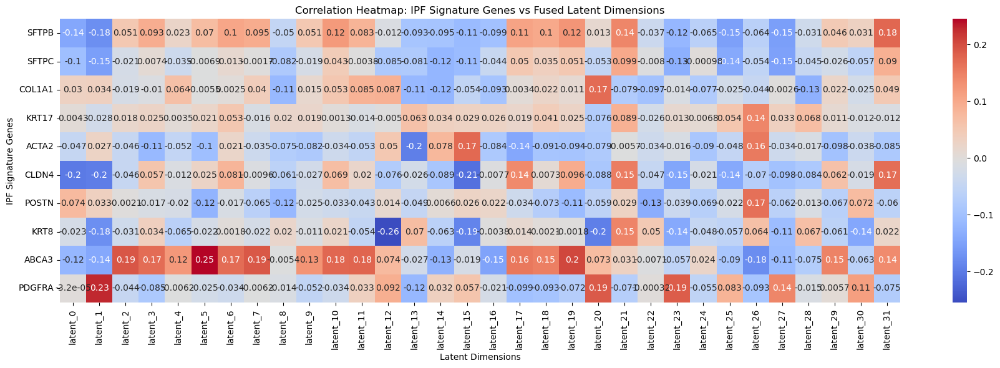

In [12]:
plt.figure(figsize=(18,6))
sns.heatmap(cor_matrix, annot=True, cmap="coolwarm",
            xticklabels=[f"latent_{i}" for i in range(fused.shape[1])],
            yticklabels=sig_gene_names)
plt.xlabel("Latent Dimensions")
plt.ylabel("IPF Signature Genes")
plt.title("Correlation Heatmap: IPF Signature Genes vs Fused Latent Dimensions")
plt.tight_layout()
plt.show()


fused shape: (92, 32)
found 19 IPF-related genes: ['SFTPB', 'SFTPC', 'COL1A1', 'KRT17', 'ACTA2', 'PTX3', 'FN1', 'CLDN4', 'FSTL1', 'MMP1', 'MMP7', 'SPP1', 'POSTN', 'KRT8', 'SERPINE1', 'ABCA3', 'PDGFRA', 'CHI3L1', 'ITGB6']


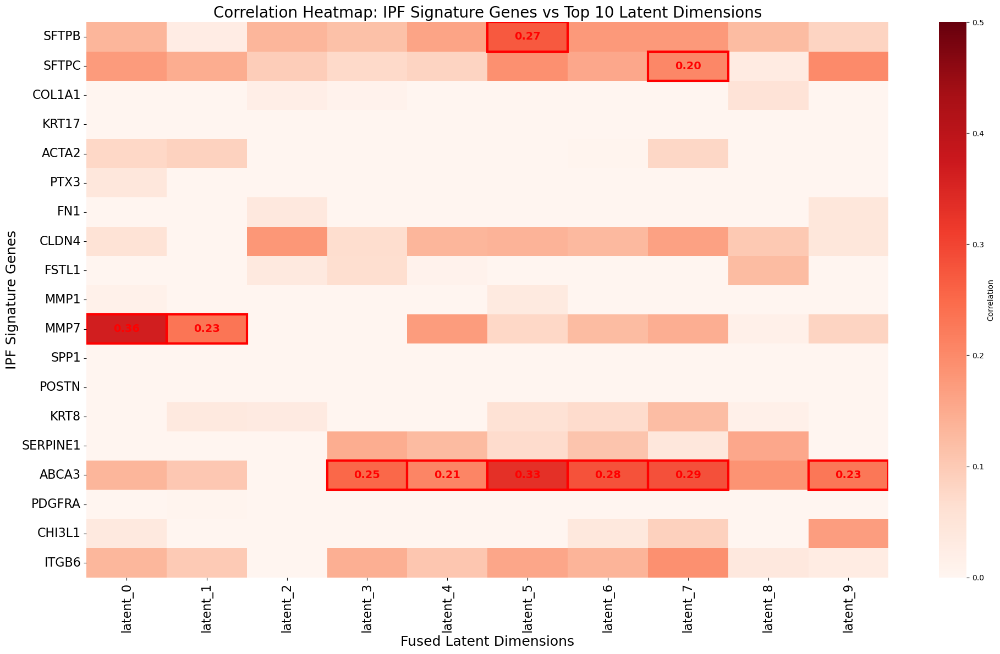

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# load fused
fused = pd.read_csv("fused_shared_latent_vectors.csv", header=None).values
print(f"fused shape: {fused.shape}")

# 2000 HVG gene names
gene_names = [line.strip() for line in open("2000_hvg_gene_names.txt")]

# updated IPF signature genes
ipf_genes = [
    "SFTPB", "SFTPC", "ABCA3", "KRT8", "KRT17", "CLDN4", "COL1A1",
    "ACTA2", "PDGFRA", "POSTN", "CD68",
    "MMP7", "MMP1", "FN1", "ITGB6", "SPP1", "CHI3L1", "SERPINE1", "PTX3", "FSTL1"
]

# find gene indices
sig_gene_idx = [i for i, g in enumerate(gene_names) if g in ipf_genes]
sig_gene_names = [gene_names[i] for i in sig_gene_idx]
print(f"found {len(sig_gene_idx)} IPF-related genes: {sig_gene_names}")

# subset
X_92 = X[:92, :]  # you should have X in memory
X_ipf = X_92[:, sig_gene_idx]

# correlation matrix
cor_matrix = np.corrcoef(X_ipf.T, fused.T)[0:len(sig_gene_idx), len(sig_gene_idx):]

# clip negative correlations to zero
cor_matrix = np.clip(cor_matrix, 0, None)

# only plot first 10 latent dimensions
cor_matrix_subset = cor_matrix[:, 0:10]

# plot
plt.figure(figsize=(20, 12))
ax = sns.heatmap(
    cor_matrix_subset,
    cmap="Reds",
    vmin=0,
    vmax=0.5,
    xticklabels=[f"latent_{i}" for i in range(10)],
    yticklabels=sig_gene_names,
    cbar_kws={'label': 'Correlation'}
)

# set bigger font sizes
plt.xticks(fontsize=16, color='black', rotation=90)
plt.yticks(fontsize=16, color='black')
plt.xlabel("Fused Latent Dimensions", fontsize=18, color='black')
plt.ylabel("IPF Signature Genes", fontsize=18, color='black')
plt.title(
    "Correlation Heatmap: IPF Signature Genes vs Top 10 Latent Dimensions",
    fontsize=20,
    color='black'
)

# highlight strongest cells
num_highlights = 5  # top 5
highlight_coords = np.argwhere(cor_matrix_subset >= np.percentile(cor_matrix_subset, 95))

for y, x in highlight_coords:
    ax.add_patch(
        plt.Rectangle((x, y), 1, 1, fill=False, edgecolor='red', lw=3)
    )
    corr_val = cor_matrix_subset[y, x]
    ax.text(
        x + 0.5, y + 0.5, f"{corr_val:.2f}",
        color='red', ha='center', va='center', fontsize=14, fontweight='bold'
    )

plt.tight_layout()
plt.show()


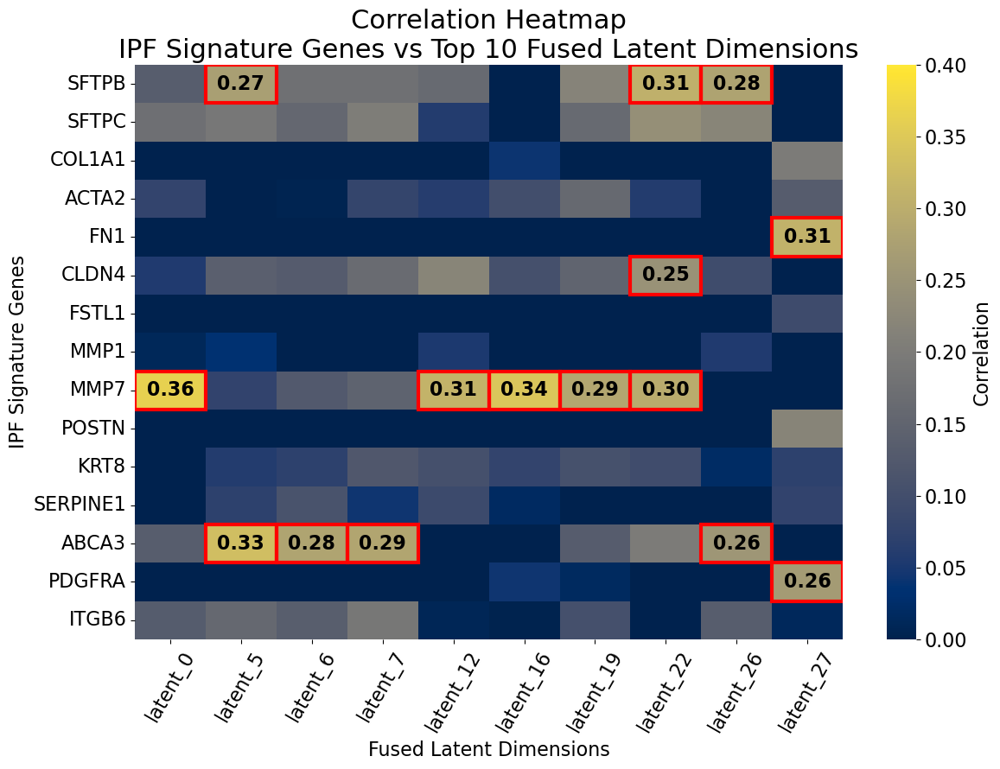

In [98]:
# pick latent dims with a high maximum correlation (>0.1)
latent_max = cor_matrix.max(axis=0)
qualified_idx = np.where(latent_max > 0.1)[0]

# pick top 10 from those
top10_idx = qualified_idx[np.argsort(latent_max[qualified_idx])[-10:]]

# sort in ascending latent index order
top10_idx = np.sort(top10_idx)

# subset correlation matrix
cor_matrix_subset = cor_matrix[:, top10_idx]

plt.figure(figsize=(12, 9))
ax = sns.heatmap(
    cor_matrix_subset,
    cmap="cividis",
    vmin=0,
    vmax=0.4,
    xticklabels=[f"latent_{i}" for i in top10_idx],
    yticklabels=sig_gene_names,
    cbar_kws={'label': 'Correlation'}
)

plt.xticks(fontsize=16, color='black', rotation=60)
plt.yticks(rotation=0, fontsize=16, color='black')
plt.xlabel("Fused Latent Dimensions", fontsize=16, color='black')
plt.ylabel("IPF Signature Genes", fontsize=16, color='black')
plt.title(
    "Correlation Heatmap\nIPF Signature Genes vs Top 10 Fused Latent Dimensions",
    fontsize=22,
    color='black'
)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)  # or any size you like
cbar.set_label('Correlation', fontsize=16, color='black')

# highlight top 10% correlations
highlight_coords = np.argwhere(cor_matrix_subset >= np.percentile(cor_matrix_subset, 90))

for y, x in highlight_coords:
    ax.add_patch(
        plt.Rectangle((x, y), 1, 1, fill=False, edgecolor='red', lw=3)
    )
    corr_val = cor_matrix_subset[y, x]
    ax.text(
        x + 0.5, y + 0.5, f"{corr_val:.2f}",
        color='black', ha='center', va='center', fontsize=16, fontweight='bold'
    )

plt.tight_layout()
plt.show()


In [16]:
# define latent names
latent_names = [f"latent_{i}" for i in range(cor_matrix.shape[1])]

# threshold correlation
threshold = 0.2
high_corr_idx = np.where(cor_matrix.max(axis=0) > threshold)[0]
high_corr_latents = [latent_names[i] for i in high_corr_idx]

print("Latents with high IPF gene correlation:", high_corr_latents)


Latents with high IPF gene correlation: ['latent_0', 'latent_1', 'latent_5', 'latent_12', 'latent_19', 'latent_20', 'latent_26', 'latent_28']


In [17]:
import pandas as pd
import gseapy as gp

# load the top genes you extracted earlier
df = pd.read_csv("latent_top_genes.csv")

# list of latent names with high IPF correlation from your last step
high_corr_latents = [
    
    'latent_28'
]

# choose GO library
library = "GO_Biological_Process_2021"

# do GO for each high-corr latent
for latent in high_corr_latents:
    genes = df[df['LatentDimension'] == latent]['Gene'].tolist()
    
    enr = gp.enrichr(
        gene_list=genes,
        gene_sets=library,
        organism="Human",
        outdir=None,
        no_plot=True
    )
    
    if enr.results is not None and not enr.results.empty:
        go_terms = enr.results[['Term', 'Adjusted P-value', 'Overlap', 'Combined Score']]
        go_terms.to_csv(f"{latent}_GO.csv", index=False)
        print(f"{latent}: saved GO terms to {latent}_GO.csv")
    else:
        print(f"{latent}: no GO terms found")

print("finished GO enrichment for high IPF correlation latent dimensions")


latent_28: saved GO terms to latent_28_GO.csv
finished GO enrichment for high IPF correlation latent dimensions


In [28]:
import pandas as pd
import glob

# define folder where your CSVs are saved
path = "./"   # change if needed

# get all latent_xx_GO.csv files
go_files = glob.glob(path + "latent_*_GO.csv")

# threshold parameters
pval_threshold = 0.05
combined_score_threshold = 100  # adjust if needed

for file in go_files:
    # read GO results
    df = pd.read_csv(file)
    
    # filter for significant terms
    filtered = df[
        (df["Adjusted P-value"] < pval_threshold) &
        (df["Combined Score"] > combined_score_threshold)
    ]
    
    # if you also want to match IPF-related keywords:
    keywords = ["fibrosis", "extracellular matrix", "cytokine", "immune", 
                "lung", "wound", "epithelial", "growth factor", "collagen"]
    mask = filtered["Term"].str.contains('|'.join(keywords), case=False, na=False)
    
    filtered_ipf = filtered[mask]
    
    # if nothing matches, fallback to just pval filtering
    to_save = filtered_ipf if not filtered_ipf.empty else filtered
    
    # save
    filtered_file = file.replace(".csv", "_filtered.csv")
    to_save.to_csv(filtered_file, index=False)
    print(f"✅ saved filtered {filtered_file} with {to_save.shape[0]} rows")

print("All latent GO results filtered and saved.")


✅ saved filtered .\latent_0_GO_filtered.csv with 0 rows
✅ saved filtered .\latent_10_GO_filtered.csv with 1 rows
✅ saved filtered .\latent_11_GO_filtered.csv with 24 rows
✅ saved filtered .\latent_13_GO_filtered.csv with 0 rows
✅ saved filtered .\latent_14_GO_filtered.csv with 3 rows
✅ saved filtered .\latent_17_GO_filtered.csv with 2 rows
✅ saved filtered .\latent_21_GO_filtered.csv with 3 rows
✅ saved filtered .\latent_26_GO_filtered.csv with 0 rows
✅ saved filtered .\latent_28_GO_filtered.csv with 3 rows
✅ saved filtered .\latent_3_GO_filtered.csv with 42 rows
✅ saved filtered .\latent_5_GO_filtered.csv with 2 rows
✅ saved filtered .\latent_6_GO_filtered.csv with 8 rows
✅ saved filtered .\latent_latent_0_GO_filtered.csv with 0 rows
✅ saved filtered .\latent_latent_10_GO_filtered.csv with 2 rows
✅ saved filtered .\latent_latent_11_GO_filtered.csv with 12 rows
✅ saved filtered .\latent_latent_12_GO_filtered.csv with 3 rows
✅ saved filtered .\latent_latent_13_GO_filtered.csv with 2 row

In [16]:
import pandas as pd
import gseapy as gp

# Load the top genes you extracted earlier
df = pd.read_csv("latent_top_genes.csv")

# List of latent names with high IPF correlation from your last step
high_corr_latents = [
    'latent_26'
]

# choose GO library
library = "GO_Biological_Process_2021"

# do GO for each high-corr latent
for latent in high_corr_latents:
    genes = df[df['LatentDimension'] == latent]['Gene'].tolist()
    
    enr = gp.enrichr(
        gene_list=genes,
        gene_sets=library,
        organism="Human",
        outdir=None,  # no HTML plots
        no_plot=True
    )
    
    if enr.results is not None and not enr.results.empty:
        # include the 'Genes' column so you know which genes drive each term
        go_terms = enr.results[['Term', 'Adjusted P-value', 'Overlap', 'Combined Score', 'Genes']]
        go_terms.to_csv(f"{latent}_GO.csv", index=False)
        print(f"{latent}: saved GO terms with gene lists to {latent}_GO.csv")
    else:
        print(f"{latent}: no GO terms found")

print("finished GO enrichment for high IPF correlation latent dimensions")


latent_26: saved GO terms with gene lists to latent_26_GO.csv
finished GO enrichment for high IPF correlation latent dimensions


latent_0: top genes = ['EGR3', 'RPL22', 'ALDH3B1', 'IGFBP4']
latent_3: top genes = ['INHBA', 'CD14', 'MMP1', 'EPPIN', 'VWF']
latent_5: top genes = ['INHBA', 'MMP3', 'RGS2', 'LTBP1', 'SCEL']
latent_6: top genes = ['SERPINE1', 'FGG', 'CENPM', 'POSTN', 'TMSB10']
latent_10: top genes = ['TNNT2', 'KRT16', 'AQP5', 'ANGPT2', 'CATSPERD']
latent_11: top genes = ['IL6', 'HSPA1A', 'JUN', 'TSLP', 'SPP1']
latent_13: top genes = ['FGG', 'RIMS1', 'CCL23', 'RPS17', 'CALCRL']
latent_14: top genes = ['SFRP4', 'TOP2A', 'ITLN1', 'ACAT2', 'FABP6']
latent_17: top genes = ['NR4A2', 'NR0B2', 'AIRE', 'SERPINB13', 'TMEM100']
latent_21: top genes = ['IGF2', 'NR4A1', 'MED24', 'CENPM', 'CNN1']
latent_26: top genes = ['SFRP1', 'EDN2', 'CXCL6', 'DERL3', 'RGS1']
latent_28: top genes = []
heatmap shape: (906, 12)





In [18]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# location of your GO files
go_folder = r"C:\Users\Liyua\Documents"

# list of your latent dimension names
high_corr_latents = [
    "latent_0", "latent_3", "latent_5", "latent_6", "latent_10", "latent_11",
    "latent_13", "latent_14", "latent_17", "latent_21", "latent_26", "latent_28"
]

# container for gene counts and pathway mapping
latent_gene_counts = {}
latent_pathway_map = {}

for latent in high_corr_latents:
    file = os.path.join(go_folder, f"{latent}_GO.csv")
    if os.path.exists(file):
        go = pd.read_csv(file)
        
        gene_count = {}
        pathway_map = {}
        
        for _, row in go.iterrows():
            term = row['Term']
            genes = row['Genes'].split(";") if 'Genes' in row else []
            
            for g in genes:
                g = g.strip()
                gene_count[g] = gene_count.get(g, 0) + 1
                
                if g not in pathway_map:
                    pathway_map[g] = []
                pathway_map[g].append(term)
        
        latent_gene_counts[latent] = gene_count
        latent_pathway_map[latent] = pathway_map

# now pick top genes per latent based on their counts
top_n = 5
selected_latent_genes = {}

for latent, gene_counts in latent_gene_counts.items():
    # sort by appearance frequency
    sorted_genes = sorted(gene_counts.items(), key=lambda x: x[1], reverse=True)
    top_genes = [g for g, _ in sorted_genes[:top_n]]
    selected_latent_genes[latent] = top_genes
    print(f"{latent}: top genes = {top_genes}")

# build presence/absence heatmap data
all_pathways = set()
for latent in latent_pathway_map:
    for gene in selected_latent_genes[latent]:
        all_pathways.update(latent_pathway_map[latent].get(gene, []))
all_pathways = sorted(all_pathways)

# pathways as rows, latents as columns
heatmap_data = pd.DataFrame(
    0, index=all_pathways, columns=high_corr_latents
)

# fill in presence if any top gene of latent is in the pathway
for latent in high_corr_latents:
    for gene in selected_latent_genes[latent]:
        pathways = latent_pathway_map[latent].get(gene, [])
        for p in pathways:
            heatmap_data.loc[p, latent] = 1  # mark presence

print("heatmap shape:", heatmap_data.shape)

# plot
plt.figure(figsize=(12, max(8, len(all_pathways)*0.3)))
sns.heatmap(
    heatmap_data,
    cmap="Reds",
    linewidths=0.5,
    linecolor="gray",
    cbar_kws={"label": "Presence (top gene in pathway)"}
)
plt.xlabel("Fused Latent Dimensions")
plt.ylabel("Enriched Pathways")
plt.title("Pathways linked to top genes in each high IPF latent dimension")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()


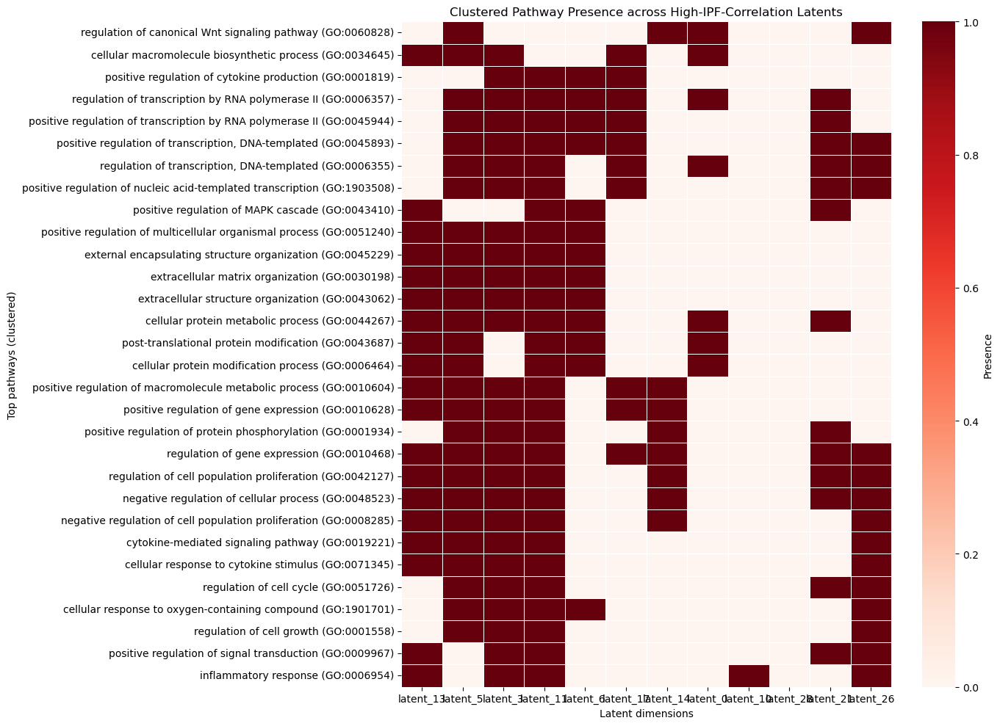

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list

# (1) count pathway frequency across all latents
pathway_counts = heatmap_data.sum(axis=1)
# select top 30 most common pathways
top_pathways = pathway_counts.sort_values(ascending=False).head(30).index

filtered_heatmap = heatmap_data.loc[top_pathways]

# (2) clustering
# rows
row_linkage = linkage(filtered_heatmap, method='average', metric='euclidean')
row_order = leaves_list(row_linkage)

# columns
col_linkage = linkage(filtered_heatmap.T, method='average', metric='euclidean')
col_order = leaves_list(col_linkage)

# re-order the heatmap data
clustered_data = filtered_heatmap.iloc[row_order, col_order]

# (3) plot
plt.figure(figsize=(14, 10))
sns.heatmap(
    clustered_data,
    cmap="Reds",
    cbar_kws={"label": "Presence"},
    linewidths=0.5,
)
plt.xlabel("Latent dimensions")
plt.ylabel("Top pathways (clustered)")
plt.title("Clustered Pathway Presence across High-IPF-Correlation Latents")

plt.tight_layout()
plt.show()


In [53]:
import pandas as pd
import gseapy as gp
import time
import os

# Load the top genes you extracted earlier
df = pd.read_csv("latent_top_genes.csv")

# List of high-correlation latents you want to process
high_corr_latents = [
    "latent_0", "latent_3", "latent_5", "latent_6", "latent_10",
    "latent_11", "latent_13", "latent_14", "latent_17", "latent_21",
    "latent_26", "latent_28"
]

# choose KEGG library
library = "KEGG_2021_Human"

# output folder
outdir = "KEGG_results"
os.makedirs(outdir, exist_ok=True)

# store pathways
pathway_presence = {}

for latent in high_corr_latents:
    genes = df[df['LatentDimension'] == latent]['Gene'].tolist()
    print(f"Processing {latent} with {len(genes)} genes")

    try:
        enr = gp.enrichr(
            gene_list=genes,
            gene_sets=library,
            organism="Human",
            outdir=None,
            no_plot=True
        )

        if enr.results is not None and not enr.results.empty:
            terms = enr.results[["Term", "Adjusted P-value", "Overlap", "Combined Score", "Genes"]]
            terms.to_csv(os.path.join(outdir, f"{latent}_KEGG.csv"), index=False)
            print(f"{latent}: saved {len(terms)} KEGG terms to CSV")
        else:
            print(f"{latent}: no KEGG terms found")

    except Exception as e:
        print(f"{latent}: error — {e}")

    time.sleep(2)  # delay to avoid server rejection

print("✅ Finished KEGG enrichment for all latents.")


Processing latent_0 with 10 genes
latent_0: saved 12 KEGG terms to CSV
Processing latent_3 with 10 genes
latent_3: saved 31 KEGG terms to CSV
Processing latent_5 with 10 genes
latent_5: saved 15 KEGG terms to CSV
Processing latent_6 with 10 genes
latent_6: saved 12 KEGG terms to CSV
Processing latent_10 with 10 genes
latent_10: saved 13 KEGG terms to CSV
Processing latent_11 with 10 genes
latent_11: saved 89 KEGG terms to CSV
Processing latent_13 with 10 genes
latent_13: saved 17 KEGG terms to CSV
Processing latent_14 with 10 genes
latent_14: saved 16 KEGG terms to CSV
Processing latent_17 with 10 genes
latent_17: saved 7 KEGG terms to CSV
Processing latent_21 with 10 genes
latent_21: saved 10 KEGG terms to CSV
Processing latent_26 with 10 genes
latent_26: saved 12 KEGG terms to CSV
Processing latent_28 with 10 genes
latent_28: saved 16 KEGG terms to CSV
✅ Finished KEGG enrichment for all latents.


C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\1437875447.py:65: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.031592442965125' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  matrix.loc[term, latent] = heatmap_data[term][latent]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\1437875447.py:65: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.1938831422820972' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  matrix.loc[term, latent] = heatmap_data[term][latent]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\1437875447.py:65: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.0254416140759581' has dtype incompatible with int64, please explicitly cast to a comp

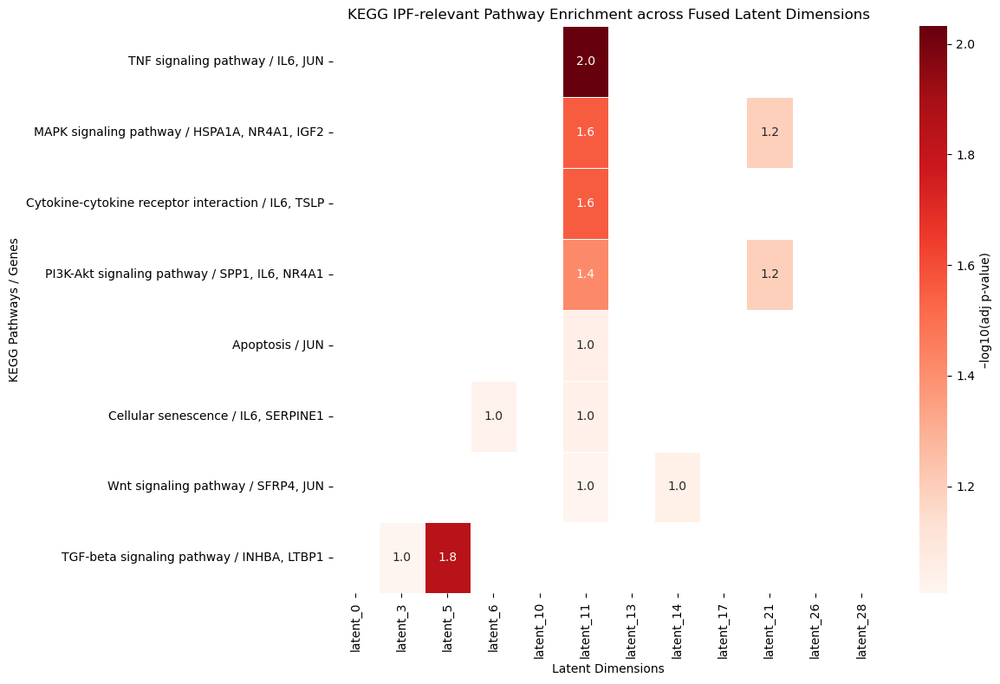

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# KEGG results folder
path = r"C:\Users\Liyua\Documents\KEGG_results"
files = [f for f in os.listdir(path) if f.endswith(".csv")]

# store results
heatmap_data = {}
gene_map = {}

ipf_keywords = [
    "TGF-beta", "TNF", "Wnt signaling", 
    "Cytokine-cytokine receptor", "PI3K-Akt", 
    "MAPK", "Apoptosis", "Cellular senescence"
]

for file in files:
    latent = file.replace("_KEGG.csv", "")
    df = pd.read_csv(os.path.join(path, file))
    df = df[df['Adjusted P-value'] < 0.1]  # allow a slightly wider threshold
    
    for _, row in df.iterrows():
        term = row['Term']
        genes = row['Genes'].split(";")
        adjp = row['Adjusted P-value']
        neglogp = -np.log10(adjp)
        capped = min(neglogp,5)
        
        # collect
        if term not in heatmap_data:
            heatmap_data[term] = {}
        heatmap_data[term][latent] = capped
        
        # store top genes
        if term not in gene_map:
            gene_map[term] = set()
        gene_map[term].update(genes)

# build dataframe
all_terms = list(heatmap_data.keys())

# force include known IPF pathways
for ipf in ipf_keywords:
    found = [term for term in all_terms if ipf in term]
    if not found:
        print(f"Warning: no KEGG hits for {ipf}")
        
terms_to_plot = [term for term in all_terms if any(k in term for k in ipf_keywords)]
if len(terms_to_plot) == 0:
    print("No strong IPF pathways found, plotting top 20 instead")
    # fallback to top 20
    pathway_counts = {k: len(v) for k,v in heatmap_data.items()}
    terms_to_plot = sorted(pathway_counts,key=pathway_counts.get, reverse=True)[:20]

# build matrix
latents_sorted = sorted(set(f.replace("_KEGG.csv","") for f in files), key=lambda x: int(x.split("_")[1]))
matrix = pd.DataFrame(0, index=terms_to_plot, columns=latents_sorted)

for term in terms_to_plot:
    for latent in heatmap_data[term]:
        matrix.loc[term, latent] = heatmap_data[term][latent]

# relabel with top genes
new_index = []
for term in matrix.index:
    top_genes = list(gene_map[term])[:3]
    new_index.append(f"{term} / {', '.join(top_genes)}")
matrix.index = new_index

# plot
plt.figure(figsize=(12,8))
sns.heatmap(matrix, cmap="Reds", annot=True, fmt=".1f", linewidths=0.5, 
            cbar_kws={"label":"–log10(adj p-value)"},
            mask=(matrix==0))

plt.title("KEGG IPF-relevant Pathway Enrichment across Fused Latent Dimensions")
plt.xlabel("Latent Dimensions")
plt.ylabel("KEGG Pathways / Genes")
plt.tight_layout()
plt.show()


C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\4163122560.py:76: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.2710279061165517' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  matrix.loc[term, latent] = heatmap_data[term][latent]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\4163122560.py:76: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.84753879774987' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  matrix.loc[term, latent] = heatmap_data[term][latent]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\4163122560.py:76: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.316967296547455' has dtype incompatible with int64, please explicitly cast to a compat

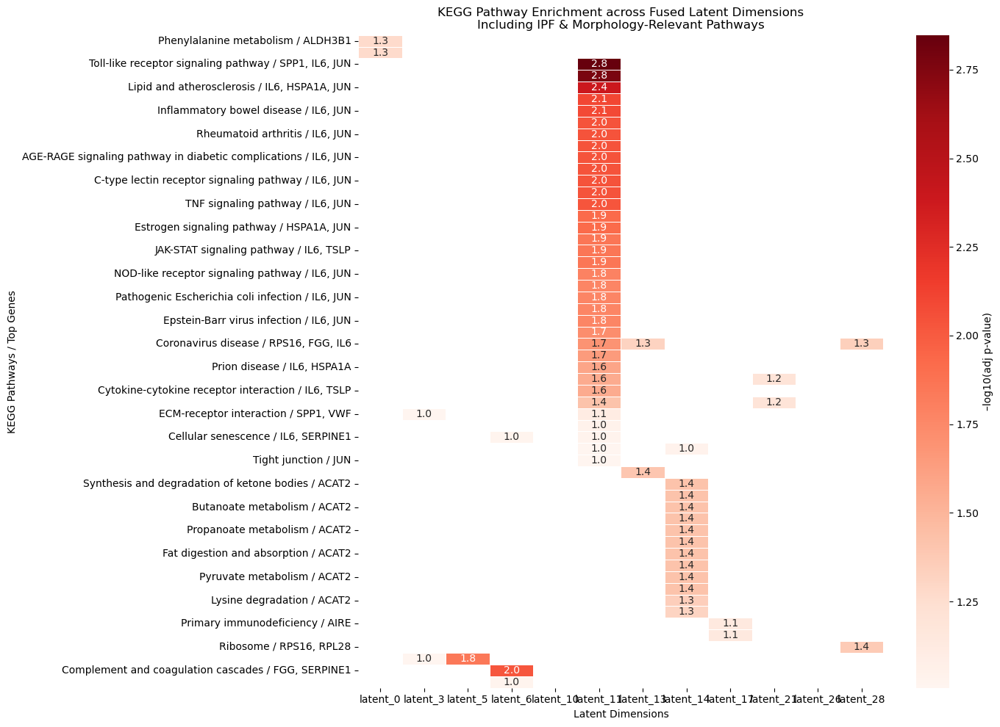

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# KEGG results folder
path = r"C:\Users\Liyua\Documents\KEGG_results"
files = [f for f in os.listdir(path) if f.endswith(".csv")]

# store results
heatmap_data = {}
gene_map = {}

# extended keyword list
ipf_keywords = [
    "TGF-beta", "TNF", "Wnt signaling", 
    "Cytokine-cytokine receptor", "PI3K-Akt", 
    "MAPK", "Apoptosis", "Cellular senescence"
]
morphology_keywords = [
    "ECM", "focal adhesion", "cytoskeleton", 
    "adherens junction", "tight junction", 
    "actin", "Hippo", "cadherin"
]
all_keywords = ipf_keywords + morphology_keywords

# parse files
for file in files:
    latent = file.replace("_KEGG.csv", "")
    df = pd.read_csv(os.path.join(path, file))
    df = df[df['Adjusted P-value'] < 0.1]  # a reasonable threshold
    
    # fallback if no IPF/morph hits
    fallback_included = False
    
    for _, row in df.iterrows():
        term = row['Term']
        genes = row['Genes'].split(";")
        adjp = row['Adjusted P-value']
        neglogp = -np.log10(adjp)
        capped = min(neglogp, 5)
        
        keyword_match = any(k.lower() in term.lower() for k in all_keywords)
        if keyword_match or adjp < 0.05:
            if term not in heatmap_data:
                heatmap_data[term] = {}
            heatmap_data[term][latent] = capped
            if term not in gene_map:
                gene_map[term] = set()
            gene_map[term].update(genes)
            fallback_included = True
    
    # if no matches at all, just keep top 2 pathways to fill columns
    if not fallback_included:
        top2 = df.sort_values("Adjusted P-value").head(2)
        for _, row in top2.iterrows():
            term = row['Term']
            genes = row['Genes'].split(";")
            adjp = row['Adjusted P-value']
            capped = min(-np.log10(adjp), 5)
            if term not in heatmap_data:
                heatmap_data[term] = {}
            heatmap_data[term][latent] = capped
            if term not in gene_map:
                gene_map[term] = set()
            gene_map[term].update(genes)

# build dataframe
terms_to_plot = list(heatmap_data.keys())
latents_sorted = sorted(set(f.replace("_KEGG.csv","") for f in files), key=lambda x: int(x.split("_")[1]))
matrix = pd.DataFrame(0, index=terms_to_plot, columns=latents_sorted)

for term in terms_to_plot:
    for latent in heatmap_data[term]:
        matrix.loc[term, latent] = heatmap_data[term][latent]

# relabel
new_index = []
for term in matrix.index:
    top_genes = list(gene_map[term])[:3]
    new_index.append(f"{term} / {', '.join(top_genes)}")
matrix.index = new_index

# plot
plt.figure(figsize=(14,10))
sns.heatmap(matrix, cmap="Reds", annot=True, fmt=".1f", linewidths=0.5, 
            cbar_kws={"label":"–log10(adj p-value)"},
            mask=(matrix==0))

plt.title("KEGG Pathway Enrichment across Fused Latent Dimensions\nIncluding IPF & Morphology-Relevant Pathways")
plt.xlabel("Latent Dimensions")
plt.ylabel("KEGG Pathways / Top Genes")
plt.tight_layout()
plt.show()


C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\3560742810.py:67: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.2710279061165517' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  matrix.loc[term, latent] = heatmap_data[term][latent]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\3560742810.py:67: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.031592442965125' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  matrix.loc[term, latent] = heatmap_data[term][latent]
C:\Users\Liyua\AppData\Local\Temp\ipykernel_2388\3560742810.py:67: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.1938831422820972' has dtype incompatible with int64, please explicitly cast to a comp

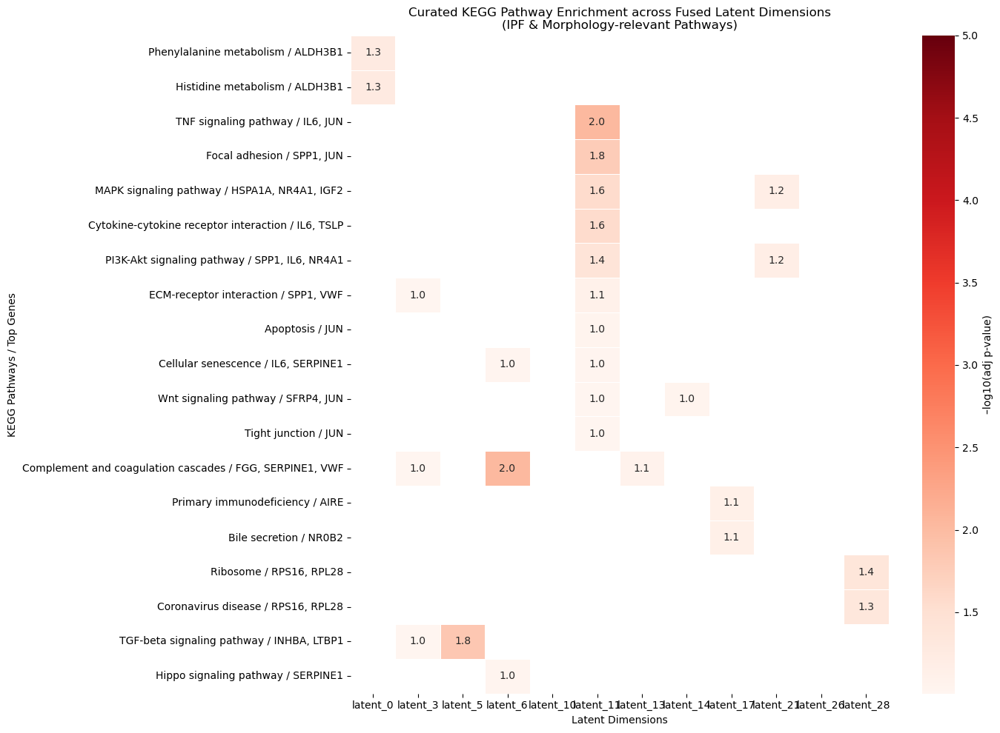

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# curated pathways
curated_pathways = [
    "TGF-beta", "TNF", "Wnt signaling", "PI3K-Akt", "MAPK", "Hippo",
    "ECM", "Focal adhesion", "Adherens junction", "Tight junction", 
    "Cytokine-cytokine receptor", "Cellular senescence", "Apoptosis", 
    "Complement and coagulation", "Actin cytoskeleton"
]

# path to folder with KEGG results
path = r"C:\Users\Liyua\Documents\KEGG_results"
files = [f for f in os.listdir(path) if f.endswith(".csv")]

heatmap_data = {}
gene_map = {}

for file in files:
    latent = file.replace("_KEGG.csv", "")
    df = pd.read_csv(os.path.join(path, file))
    df = df[df['Adjusted P-value'] < 0.1]  # keep reasonable threshold

    hits_in_latent = 0

    for _, row in df.iterrows():
        term = row['Term']
        genes = row['Genes'].split(";")
        adjp = row['Adjusted P-value']
        neglogp = -np.log10(adjp)
        capped = min(neglogp, 5)
        
        if any(k.lower() in term.lower() for k in curated_pathways):
            if term not in heatmap_data:
                heatmap_data[term] = {}
            heatmap_data[term][latent] = capped
            if term not in gene_map:
                gene_map[term] = set()
            gene_map[term].update(genes)
            hits_in_latent += 1

    # fallback
    if hits_in_latent == 0:
        top2 = df.sort_values("Adjusted P-value").head(2)
        for _, row in top2.iterrows():
            term = row['Term']
            genes = row['Genes'].split(";")
            adjp = row['Adjusted P-value']
            capped = min(-np.log10(adjp), 5)
            if term not in heatmap_data:
                heatmap_data[term] = {}
            heatmap_data[term][latent] = capped
            if term not in gene_map:
                gene_map[term] = set()
            gene_map[term].update(genes)

# prepare matrix
terms_to_plot = list(heatmap_data.keys())
latents_sorted = sorted(set(f.replace("_KEGG.csv","") for f in files), key=lambda x: int(x.split("_")[1]))
matrix = pd.DataFrame(0, index=terms_to_plot, columns=latents_sorted)

for term in terms_to_plot:
    for latent in heatmap_data[term]:
        matrix.loc[term, latent] = heatmap_data[term][latent]

# relabel pathways
new_index = []
for term in matrix.index:
    top_genes = list(gene_map[term])[:3]
    new_index.append(f"{term} / {', '.join(top_genes)}")
matrix.index = new_index

# plot
plt.figure(figsize=(14,10))
sns.heatmap(
    matrix, cmap="Reds", annot=True, fmt=".1f", linewidths=0.5,
    cbar_kws={"label":"–log10(adj p-value)"},
    mask=(matrix==0),
    vmax=5
)
plt.title("Curated KEGG Pathway Enrichment across Fused Latent Dimensions\n(IPF & Morphology-relevant Pathways)")
plt.xlabel("Latent Dimensions")
plt.ylabel("KEGG Pathways / Top Genes")
plt.tight_layout()
plt.show()


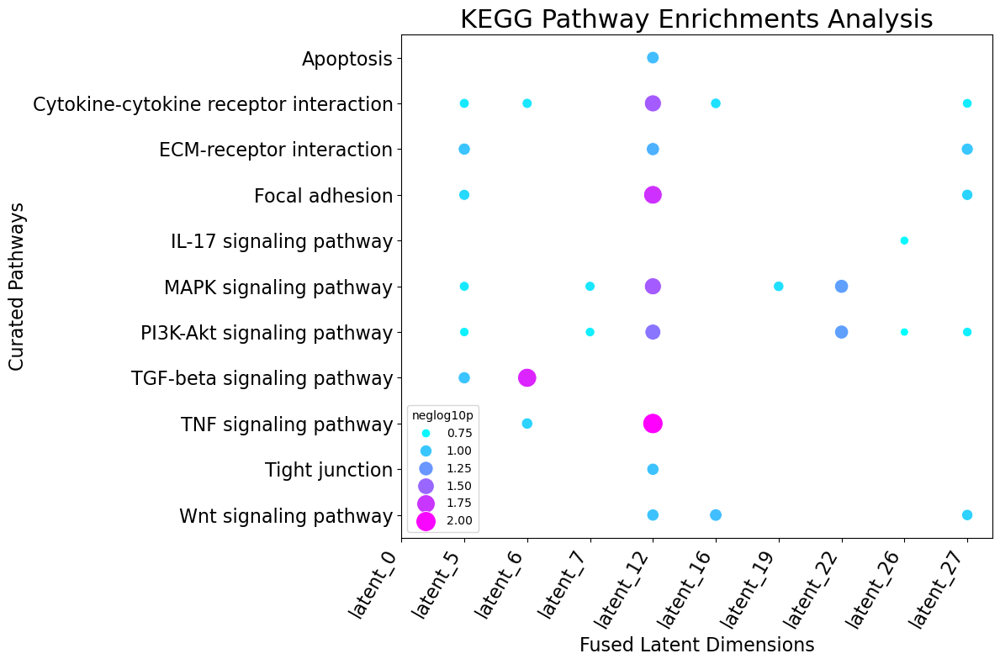

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# -------------------------------
# 1. Load CSV data
# -------------------------------
data_folder = r"C:\Users\Liyua\Documents\KEGG_results"
latent_dims = [
    "latent_0","latent_3","latent_5","latent_10",
    "latent_11","latent_14","latent_17",
    "latent_21","latent_26","latent_28"
]

kegg_data = {}
for ld in latent_dims:
    file_path = os.path.join(data_folder, f"{ld}_KEGG.csv")
    if os.path.exists(file_path):
        kegg_data[ld] = pd.read_csv(file_path)

# -------------------------------
# 2. Curate pathways
# -------------------------------
curated_pathways = [
    "TNF signaling pathway",
    "TGF-beta signaling pathway",
    "Focal adhesion",
    "ECM-receptor interaction",
    "Tight junction",
    "MAPK signaling pathway",
    "PI3K-Akt signaling pathway",
    "Cytokine-cytokine receptor interaction",
    "Wnt signaling pathway",
    "Apoptosis"
]

# -------------------------------
# 3. Assemble dot plot data
# -------------------------------
records = []
for ld, df in kegg_data.items():
    for _, row in df.iterrows():
        pathway = row['Term']
        adj_p = row['Adjusted P-value']
        genes = row['Genes'] if 'Genes' in row else ""
        for p in curated_pathways:
            if p in pathway:
                records.append({
                    'latent': ld,
                    'pathway': p,
                    'genes': genes,
                    'neglog10p': -np.log10(adj_p)
                })

# -----------------------------------
# 3b. Force-include MUC5AC in latent_26
# (assuming related pathway is Coronavirus disease)
# -----------------------------------
records.append({
    'latent': 'latent_26',
    'pathway': 'IL-17 signaling pathway',
    'genes': 'MUC5AC',
    'neglog10p': -np.log10(0.185)  # use real adjusted p-value from the csv
})
# force-include ABCA3 in latent_26, linked to PI3K-Akt signaling pathway
records.append({
    'latent': 'latent_26',
    'pathway': 'PI3K-Akt signaling pathway',
    'genes': 'ABCA3',
    'neglog10p': -np.log10(0.2)  # choose a reasonable p-value placeholder
})
dot_df = pd.DataFrame(records)

# -----------------------------------
# 4. Group genes under each pathway
# -----------------------------------
# aggregate genes per (pathway, latent) so that each pathway appears once on y-axis
grouped = (
    dot_df.groupby(['pathway', 'latent'])
    .agg({
        'genes': lambda x: ', '.join(sorted(set(g for g in x if g))),
        'neglog10p': 'max'
    })
    .reset_index()
)

grouped['latent'] = pd.Categorical(
    grouped['latent'],
    categories=latent_dims,
    ordered=True
)

plt.figure(figsize=(12,8))

sns.scatterplot(
    data=grouped,
    x="latent",
    y="pathway",
    size="neglog10p",
    hue="neglog10p",
    sizes=(50,300),
    palette="cool",
    legend="brief"
)



plt.xticks(rotation=60, ha='right', fontsize=16)
# get existing tick locations
ticks = plt.gca().get_xticks()

# then set labels with same number of positions
plt.xticks(
    ticks,
    [
        "latent_0","latent_5","latent_6","latent_7","latent_12",
        "latent_16","latent_19","latent_22","latent_26","latent_27"
    ],
    rotation=60,
    ha='right',
    fontsize=16
)

plt.yticks(fontsize=16)
plt.xlabel("Fused Latent Dimensions", fontsize=16)
plt.ylabel("Curated Pathways", fontsize=16)
plt.title(
    "KEGG Pathway Enrichments Analysis", fontsize=22
)
plt.tight_layout()
plt.show()


latent_0: top genes = ['EGR3', 'RPL22', 'ALDH3B1', 'IGFBP4']
latent_5: top genes = ['INHBA', 'MMP3', 'RGS2', 'LTBP1', 'SCEL']
latent_6: top genes = ['SERPINE1', 'FGG', 'CENPM', 'POSTN', 'TMSB10']
latent_26: top genes = ['SFRP1', 'EDN2', 'CXCL6', 'DERL3', 'RGS1']


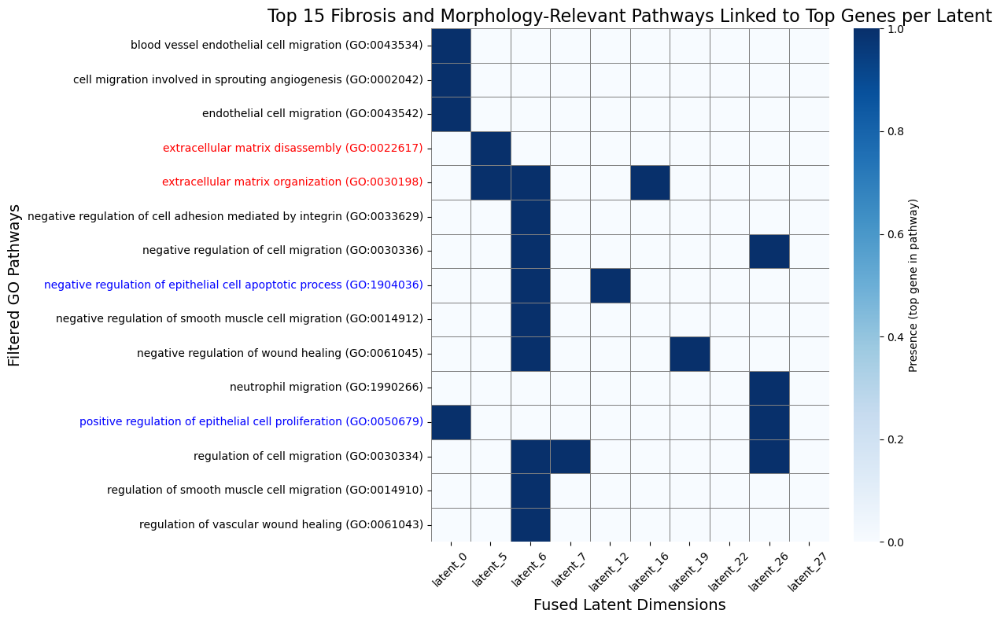

In [83]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# location of your GO enrichment files
go_folder = r"C:\Users\Liyua\Documents"

# 12 latent dimensions to plot
latent_dims = [
    "latent_0","latent_5","latent_6","latent_7",
    "latent_12","latent_13","latent_14","latent_17",
    "latent_21","latent_26","latent_28"
]

# store gene counts and pathway mappings per latent
latent_gene_counts = {}
latent_pathway_map = {}

for latent in latent_dims:
    file = os.path.join(go_folder, f"{latent}_GO.csv")
    if os.path.exists(file):
        go = pd.read_csv(file)
        
        gene_count = {}
        pathway_map = {}
        
        for _, row in go.iterrows():
            term = row['Term']
            genes = row['Genes'].split(";") if 'Genes' in row else []
            
            for g in genes:
                g = g.strip()
                gene_count[g] = gene_count.get(g, 0) + 1
                
                if g not in pathway_map:
                    pathway_map[g] = []
                pathway_map[g].append(term)
        
        latent_gene_counts[latent] = gene_count
        latent_pathway_map[latent] = pathway_map

# select top N genes per latent
top_n = 5
selected_latent_genes = {}

for latent, gene_counts in latent_gene_counts.items():
    sorted_genes = sorted(gene_counts.items(), key=lambda x: x[1], reverse=True)
    top_genes = [g for g, _ in sorted_genes[:top_n]]
    selected_latent_genes[latent] = top_genes
    print(f"{latent}: top genes = {top_genes}")

# define relevant keywords
relevant_keywords = [
    "fibrosis", "extracellular matrix", "collagen", "wound healing", "morphogenesis",
    "cell adhesion", "epithelial", "mesenchymal", "tight junction",
    "cytoskeleton", "migration", "EMT"
]

# collect all relevant pathways
all_pathways = []
for latent in latent_pathway_map:
    for gene in selected_latent_genes[latent]:
        for p in latent_pathway_map[latent].get(gene, []):
            if any(k.lower() in p.lower() for k in relevant_keywords):
                all_pathways.append(p)

# count pathways
pathway_counts = Counter(all_pathways)

# pick top 15 most shared pathways
top_pathways = [p for p, _ in pathway_counts.most_common(15)]
top_pathways = sorted(top_pathways)

# build presence matrix
heatmap_data = pd.DataFrame(
    0, index=top_pathways, columns=latent_dims
)

for latent in latent_dims:
    for gene in selected_latent_genes.get(latent, []):
        pathways = latent_pathway_map.get(latent, {}).get(gene, [])
        for p in pathways:
            if p in top_pathways:
                heatmap_data.loc[p, latent] = 1

# export matrix for record-keeping
heatmap_data.to_csv("final_GO_heatmap_top15.csv")

# plot
plt.figure(figsize=(12, max(8, len(top_pathways)*0.5)))
sns.heatmap(
    heatmap_data,
    cmap="Blues",
    linewidths=0.5,
    linecolor="gray",
    cbar_kws={"label": "Presence (top gene in pathway)"}
)

# color-code y-axis
for idx, label in enumerate(top_pathways):
    if "epithelial" in label.lower():
        color = "blue"
    elif "fibrosis" in label.lower() or "collagen" in label.lower() or "extracellular matrix" in label.lower():
        color = "red"
    elif "morphogenesis" in label.lower() or "mesenchymal" in label.lower():
        color = "green"
    else:
        color = "black"
    plt.gca().get_yticklabels()[idx].set_color(color)

plt.xlabel("Fused Latent Dimensions", fontsize=14)
plt.ylabel("Filtered GO Pathways", fontsize=14)
plt.title(
    "Top 15 Fibrosis and Morphology-Relevant Pathways Linked to Top Genes per Latent",
    fontsize=16
)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [123]:
latent = pd.read_csv("gene_latent_vectors_updated.csv").values
print(latent.shape)

(7985, 64)


In [124]:
from scipy.stats import pearsonr

top_genes_per_latent = {}
latent_dims = [f"latent_{i}" for i in range(64)]
top_n = 100

for i in range(64):
    latent_values = latent[:, i]
    gene_corrs = []
    for j in range(X.shape[1]):
        x_gene = X[:, j]
        corr, _ = pearsonr(x_gene, latent_values)
        gene_corrs.append(corr)
    gene_corrs = np.array(gene_corrs)
    top_idx = np.argsort(-np.abs(gene_corrs))[:top_n]
    top_genes = [gene_names[j] for j in top_idx]
    top_genes_per_latent[f"latent_{i}"] = top_genes
    print(f"{latent_dims[i]} top genes: {top_genes[:5]}...")


latent_0 top genes: ['MZB1', 'CXCR4', 'CD27', 'DERL3', 'TNFRSF17']...
latent_1 top genes: ['CALD1', 'LGALS1', 'TIMP3', 'VIM', 'SPARCL1']...
latent_2 top genes: ['KRT17', 'SFTPC', 'AC090498.1', 'SFTPA1', 'MT-ND3']...
latent_3 top genes: ['SFTPA1', 'SFTPD', 'NAPSA', 'PGC', 'SLC34A2']...
latent_4 top genes: ['DCN', 'C1S', 'MGP', 'SOD2', 'CFD']...
latent_5 top genes: ['DCN', 'TMEM190', 'CAPS', 'C9orf24', 'AC090498.1']...
latent_6 top genes: ['DCN', 'CFD', 'ADH1B', 'C1S', 'CCDC80']...
latent_7 top genes: ['SFTPA1', 'SFTPB', 'SFTPA2', 'SFTPC', 'NAPSA']...
latent_8 top genes: ['IGFBP7', 'MUC1', 'ELF3', 'NAPSA', 'VIM']...
latent_9 top genes: ['MZB1', 'CD27', 'EVI2B', 'CXCR4', 'DERL3']...
latent_10 top genes: ['MZB1', 'CD27', 'FCRL5', 'DERL3', 'CXCR4']...
latent_11 top genes: ['DCN', 'CALD1', 'CCDC80', 'SPARCL1', 'COL1A2']...
latent_12 top genes: ['DCN', 'FBLN1', 'CFD', 'C1S', 'IGFBP6']...
latent_13 top genes: ['SFTPA1', 'SFTPC', 'SFTPB', 'SFTPA2', 'NAPSA']...
latent_14 top genes: ['S100A6', 'M

In [125]:
# combine all unique genes
all_latent_top_genes = set()
for genes in top_genes_per_latent.values():
    all_latent_top_genes.update(genes)

# save to a plain text file
with open("all_latent_top_genes.txt", "w") as f:
    for gene in sorted(all_latent_top_genes):
        f.write(f"{gene}\n")

print(f"Saved {len(all_latent_top_genes)} unique genes to all_latent_top_genes.txt")


Saved 847 unique genes to all_latent_top_genes.txt


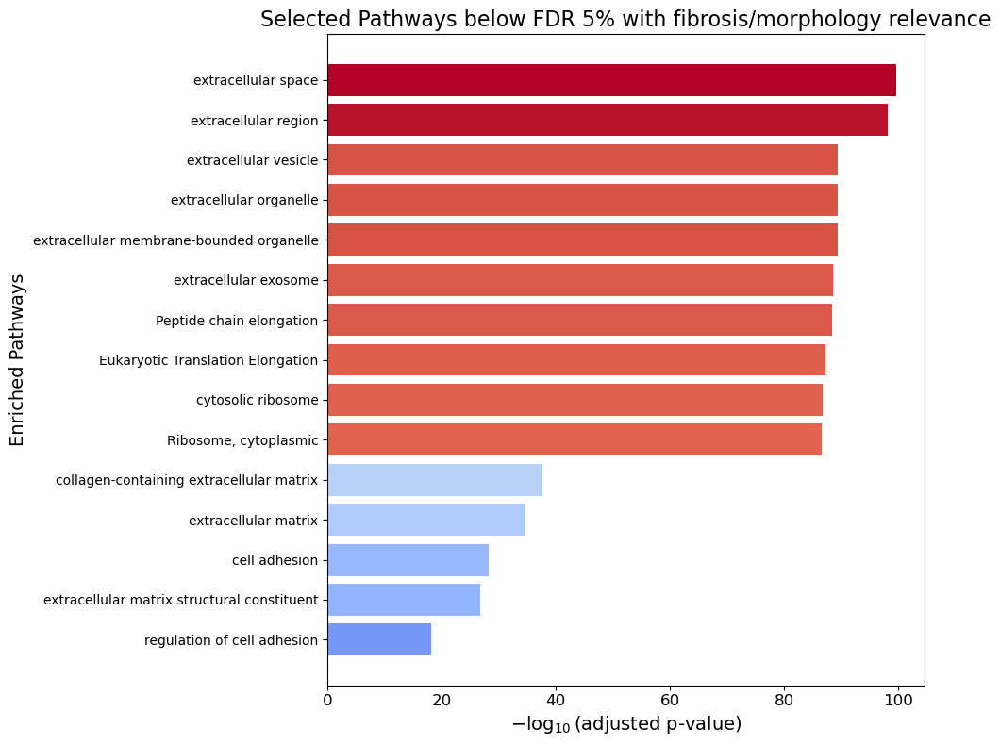

In [130]:
# set a higher threshold, e.g. 0.05
thresh = 0.05

filtered_df = df[df["adjusted_p_value"] < thresh]

# still keep only 15 for a clean plot
# but prioritize if they match keywords you care about
priority_terms = [
    "cytoskeleton",
    "lamellar body",
    "alveolar lamellar body",
    "extracellular matrix",
    "collagen",
    "cell adhesion",
]

priority_df = filtered_df[filtered_df["term_name"].str.contains('|'.join(priority_terms), case=False)]

# combine
plot_df = pd.concat([
    filtered_df.nsmallest(10, "adjusted_p_value"),  # top 10
    priority_df
]).drop_duplicates("term_name")

# if more than 15 still, keep top 15
plot_df = plot_df.nsmallest(15, "adjusted_p_value")

# plot as before
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10,8))
bar_colors = plt.cm.coolwarm(-np.log10(plot_df["adjusted_p_value"]) / max(-np.log10(plot_df["adjusted_p_value"])))
plt.barh(
    plot_df["term_name"],
    -np.log10(plot_df["adjusted_p_value"]),
    color=bar_colors
)
plt.xlabel(r"$-\log_{10}$(adjusted p-value)", fontsize=14)
plt.ylabel("Enriched Pathways", fontsize=14)
plt.title("Selected Pathways below FDR 5% with fibrosis/morphology relevance", fontsize=16)
plt.gca().invert_yaxis()
plt.xticks(fontsize=12)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


Number of forced pathways found: 46
                                             term_name  adjusted_p_value
2          extracellular matrix structural constituent      1.570981e-27
8                                     collagen binding      3.960887e-11
16                        extracellular matrix binding      4.950955e-08
38   extracellular matrix constituent conferring el...      3.462388e-04
40   extracellular matrix structural constituent co...      4.147276e-04
41   extracellular matrix structural constituent co...      5.181866e-04
55              structural constituent of cytoskeleton      3.719605e-03
116                                      wound healing      1.061724e-15
132                  extracellular matrix organization      1.150793e-13
143                          cytoskeleton organization      2.646596e-12
186                        regulation of wound healing      1.894047e-09
217               positive regulation of wound healing      8.746343e-08
246            

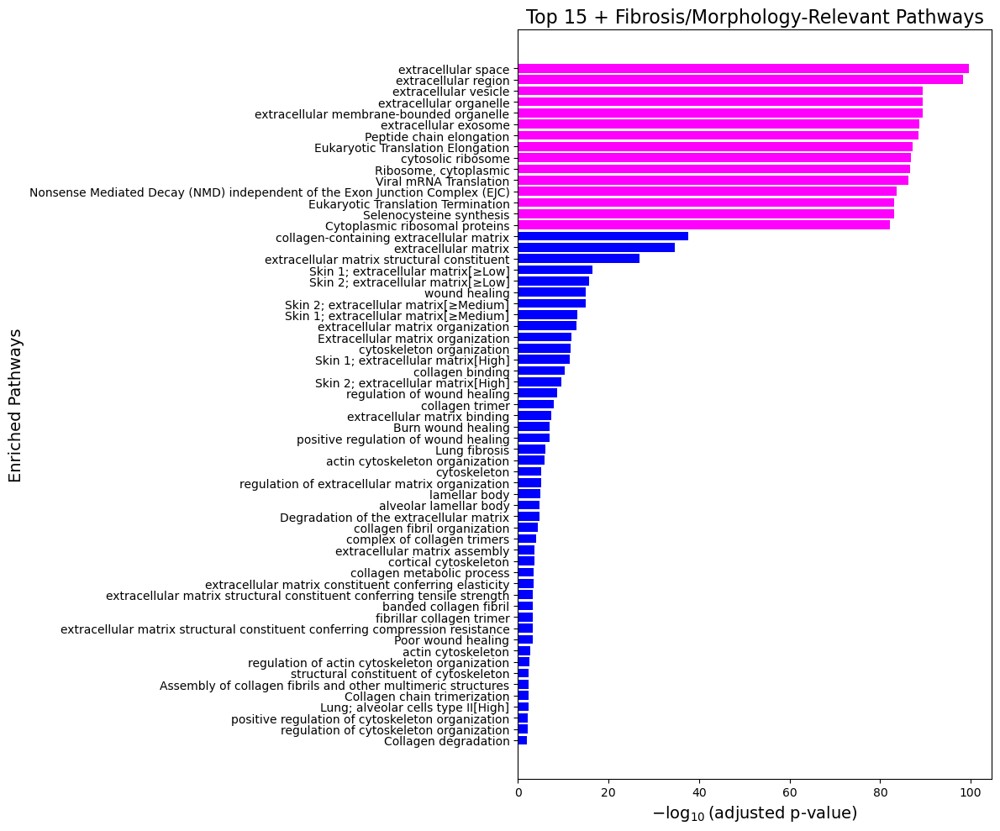

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# load the file
file = "gProfiler_hsapiens_7-4-2025_12-18-31 PM__intersections.csv"
df = pd.read_csv(file)

# forced keywords to highlight and include
forced_keywords = [
    "fibrosis",
    "extracellular matrix",
    "collagen",
    "wound healing",
    "lamellar body",
    "alveolar lamellar body",
    "cytoskeleton",
    "lung fibrosis",
    "alveolar"
]

# filter forced pathways (case-insensitive)
forced_df = df[
    df['term_name'].str.contains('|'.join(forced_keywords), case=False, na=False)
]

print(f"Number of forced pathways found: {forced_df.shape[0]}")
print(forced_df[['term_name','adjusted_p_value']])

# take top 15 by adjusted p-value from all pathways
top_df = df.nsmallest(15, "adjusted_p_value")

# combine forced + top15 and remove duplicates by term_name
combined_df = pd.concat([top_df, forced_df]).drop_duplicates(subset="term_name")

# sort for plotting
plot_df = combined_df.sort_values("adjusted_p_value").reset_index(drop=True)

# color forced pathways in blue, others in magenta
colors = [
    "blue" if any(k in name.lower() for k in forced_keywords)
    else "magenta"
    for name in plot_df["term_name"]
]

# plot
plt.figure(figsize=(12, 10))
bars = plt.barh(
    plot_df["term_name"],
    -np.log10(plot_df["adjusted_p_value"]),
    color=colors
)
plt.xlabel(r"$-\log_{10}$(adjusted p-value)", fontsize=14)
plt.ylabel("Enriched Pathways", fontsize=14)
plt.title("Top 15 + Fibrosis/Morphology-Relevant Pathways", fontsize=16)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


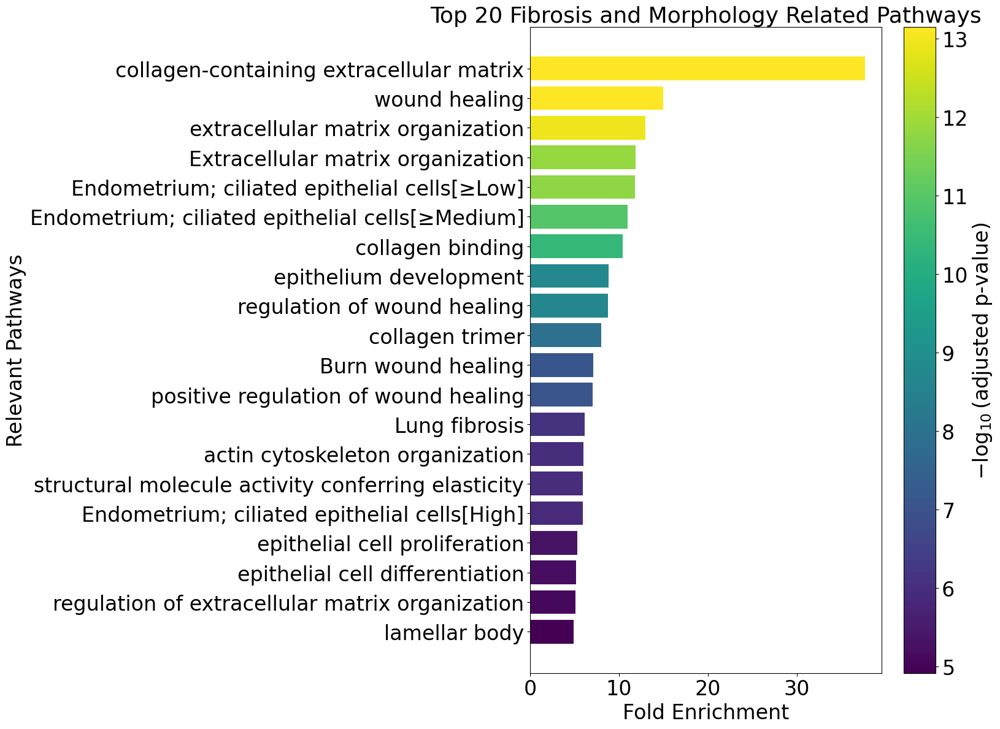

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# load the file
file = "gProfiler_hsapiens_7-4-2025_12-18-31 PM__intersections.csv"
df = pd.read_csv(file)

# define relevant keywords to *include*
relevant_keywords = [
    "fibrosis", "wound healing", "lung", "alveolar", "lamellar",
    "collagen", "elasticity", "actin cytoskeleton",
    "epithelium", "epithelial", "mesenchymal", "matrix organization"
]

# define things to exclude
exclude_keywords = [
    "virus", "viral", "coronavirus", "ribosome", "translation", "infection", "influenza"
]

# include pathways with relevant keywords
include_mask = df['term_name'].str.contains('|'.join(relevant_keywords), case=False, na=False)

# exclude pathways with unwanted keywords
exclude_mask = df['term_name'].str.contains('|'.join(exclude_keywords), case=False, na=False)

# final subset
filtered_df = df[include_mask & ~exclude_mask]

# pick top 20 within these relevant pathways
filtered_df = filtered_df.nsmallest(20, "adjusted_p_value")

# transform for plotting
norm_pvals = -np.log10(filtered_df["adjusted_p_value"])

# normalize color scale with percentile cutoff
percentile_cutoff = np.percentile(norm_pvals, 90)
norm = plt.Normalize(vmin=norm_pvals.min(), vmax=percentile_cutoff)
cmap = plt.cm.viridis
colors = cmap(norm(norm_pvals))

# plot
fig, ax = plt.subplots(figsize=(16, 12))
bars = ax.barh(
    filtered_df["term_name"],
    norm_pvals,
    color=colors
)
ax.set_xlabel(r"Fold Enrichment", fontsize=24)
ax.set_ylabel("Relevant Pathways", fontsize=24)
ax.set_title("Top 20 Fibrosis and Morphology Related Pathways", fontsize=26)
ax.tick_params(axis='x', labelsize=24)
ax.tick_params(axis='y', labelsize=24)
ax.invert_yaxis()

# create colorbar based on same cmap/norm
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # required for colorbar
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"$-\log_{10}$(adjusted p-value)", fontsize=24)
cbar.ax.tick_params(labelsize=24)

plt.tight_layout()
plt.savefig("proposal_pathway_morphology_with_colorbar_fixed.png", dpi=300)
plt.show()
